In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nfl_data_py as nfl

# Define the years to import
yrs = range(2016, 2025)
#yrs = 2022

# Play-by-Play Data
#pbp_data = nfl.import_pbp_data(years=yrs)

# Player Stats
#player_stats = nfl.import_seasonal_data(years=yrs, s_type='ALL')

# Weekly Rosters
#weekly_rosters = nfl.import_weekly_rosters(years=yrs)

# Schedules
#schedules = nfl.import_schedules(years=yrs)

# Injuries
#injuries = nfl.import_injuries(years=yrs)

# Draft Data
#draft_data = nfl.import_draft_picks(years=yrs)

# Combine Data
#combine_data = nfl.import_combine_data(years=yrs)

# Weekly Fantasy Data
weekly_fantasy_data = nfl.import_weekly_data(years=yrs)

# Officiating Data
#officiating_data = nfl.import_officials(years=yrs)

# Betting Lines
#betting_lines = nfl.import_sc_lines(yrs)

# Depth Charts
depth_charts = nfl.import_depth_charts(years=yrs)

# Next Gen Stats
#next_gen_stats = nfl.import_ngs_data(years=yrs, stat_type='passing')

Downcasting floats.


In [2]:
# 'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv'
context_forecast_df = pd.read_csv(r'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv')
context_forecast_df.head()

,game_id,play_id,epa,expected_epa,shrinked_preds,residual_epa,variance_encoder,pressure_prob,predicted_rush_yards,predicted_yac,completion_prob,pass_breakup_prob,predicted_time_to_throw
0,2016_01_NE_ARI,241.0,-0.564257,-0.258300,-0.012915,-0.551342,1.831828,0.393293,NaN,3.306424,0.410585,0.420536,1.896610
1,2016_01_NE_ARI,263.0,-0.720176,-0.076579,-0.003829,-0.716347,0.952143,NaN,5.093922,NaN,NaN,NaN,NaN
2,2016_01_NE_ARI,284.0,1.971302,-0.302733,-0.015137,1.986439,4.268127,0.450279,NaN,2.473998,0.358089,0.502799,2.254585
3,2016_01_NE_ARI,340.0,1.677589,0.021747,0.001087,1.676502,1.639341,0.328465,NaN,3.461304,0.549997,0.404134,2.092072
4,2016_01_NE_ARI,365.0,-0.416293,-0.142279,-0.007114,-0.409179,0.693973,NaN,4.067931,NaN,NaN,NaN,NaN


In [3]:
def pivot_wide_both_sides(data):
    import warnings
    warnings.filterwarnings('ignore')

    # Filter for valid play types
    data = data[data['play_type'].isin(['run', 'pass'])].copy()

    # Sort for consistency
    data = data.sort_values(['game_id', 'play_id'])

    # Helper function to expand player columns
    def expand_player_col(df, col_name):
        side = col_name.split('_')[0]  # offense or defense

        # Fill missing with empty string to allow split
        players_split = df[col_name].fillna('').str.split(';')

        # Pad each list to exactly 11 players (or truncate)
        players_list = players_split.apply(lambda lst: (lst + [None]*11)[:11])

        # Convert to DataFrame
        players_df = pd.DataFrame(players_list.tolist(), columns=[f'{side}_player_{i+1}' for i in range(11)])

        return players_df

    # Expand offense and defense player columns
    offense_wide = expand_player_col(data, 'offense_players')
    defense_wide = expand_player_col(data, 'defense_players')

    # Concatenate expanded columns with the original DataFrame
    pbp_wide = pd.concat([data.reset_index(drop=True), offense_wide, defense_wide], axis=1)

    # Drop potential duplicates
    pbp_wide = pbp_wide.drop_duplicates(subset=['game_id', 'play_id'])

    # Drop rows with NaN in offense_players or defense_players
    pbp_wide = pbp_wide.dropna(subset=['offense_players', 'defense_players'])

    return pbp_wide

In [4]:
def clean_depth_charts(depth_charts):
    # Remove duplicates on season, club_code, week, gsis_id
    depth_charts_copy = depth_charts.drop_duplicates(subset=['season', 'club_code', 'week', 'gsis_id'])
    depth_charts_copy = depth_charts_copy[depth_charts_copy['formation'].str.contains('Offense|Defense', regex=True)].copy()

    # Replace 'T' and 'G' in 'position' with the value from 'depth_position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['T', 'G']),
        depth_charts_copy['depth_position'],
        depth_charts_copy['position']
    )

    # Replace 'LOT' in 'position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['LOT']),
        'LT',
        depth_charts_copy['position']
    )

    # Replace 'ROT' in 'position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['ROT']),
        'RT',
        depth_charts_copy['position']
    )

    # Replace 'RDE' and 'LDE'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['RDE', 'LDE']),
        'DE',
        depth_charts_copy['position']
    )   

    # Replace 'RDT' and 'LDT'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['RDT', 'LDT']),
        'DT',
        depth_charts_copy['position']
    )   
    
    # Replace 'DB' with 'CB'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['LB']),
        'MLB',
        depth_charts_copy['position']
    )

    # Replace 'K', 'P', 'LS'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(["\n ", 'K', 'P', 'LS']),
        'special',
        depth_charts_copy['position']
    )

    # Replace 'DB' with 'CB'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['DB']),
        'CB',
        depth_charts_copy['position']
    )

    # Replace '\n'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].str.contains(' '),
        'special',
        depth_charts_copy['position']
    )

    # Replace 'SBBYE'
    depth_charts_copy['week'] = np.where(
        depth_charts_copy['week'].isna(),
        '23',
        depth_charts_copy['week']
    )

    # Seniority counter
    depth_charts_copy['seniority'] = depth_charts_copy.groupby(['gsis_id']).cumcount() + 1

    # Cumulative sum of depth_team per gsis_team
    depth_charts_copy['depth_team'] = depth_charts_copy['depth_team'].astype(int)
    depth_charts_copy['depth_team_sum'] = depth_charts_copy.groupby(['gsis_id'])['depth_team'].cumsum()

    # Cumulative mean of depth_team per gsis_team
    depth_charts_copy['depth_team_mean'] = depth_charts_copy['depth_team_sum'] / depth_charts_copy['seniority']

    # Sort by season, club_code, week, position, depth_team_mean
    depth_charts_copy = depth_charts_copy.sort_values(['depth_team_mean'], ascending=True)

    # Cumulative count of season, week, club_team, position
    depth_charts_copy['depth_team_estimator'] = depth_charts_copy.groupby(['season', 'week', 'club_code', 'position']).cumcount() + 1
    
    #depth_charts_copy['depth_team_estimator'] = depth_charts_copy['depth_team_estimator'].astype(int)
    depth_charts_copy['depth_team_estimator'] = depth_charts_copy['depth_team_estimator'].astype(str)

    # Define position_label
    depth_charts_copy['position_label'] = depth_charts_copy['position'] + depth_charts_copy['depth_team_estimator'].astype(str)
    depth_charts_copy['season'] = depth_charts_copy['season'].astype(int)
    depth_charts_copy['gsis_id'] = depth_charts_copy['gsis_id'].astype(str)
    depth_charts_copy['week'] = depth_charts_copy['week'].astype(str).str.replace('.0', '', regex=False).astype(int)

    return depth_charts_copy

In [5]:
def pivot_long_both_sides(pbp_wide, depth_charts):
    import warnings
    warnings.filterwarnings('ignore')
    
    # Clean depth charts
    depth_charts_clean = clean_depth_charts(depth_charts)
    
    # Combine offense and defense player columns into long format
    long_df = pd.wide_to_long(
        pbp_wide.reset_index(),
        stubnames=['offense_player', 'defense_player'],
        i=['index'],  # preserves play-wise indexing
        j='player_number',
        sep='_',
        suffix='\\d+'
    ).reset_index()
    
    # Stack both sides
    offense_df = long_df[['game_id', 'play_id', 'offense_player', 'player_number', 'season', 'week']].copy()
    offense_df.rename(columns={'offense_player': 'player_id'}, inplace=True)

    defense_df = long_df[['game_id', 'play_id', 'defense_player', 'player_number', 'season', 'week']].copy()
    defense_df.rename(columns={'defense_player': 'player_id'}, inplace=True)
    
    all_long = pd.concat([offense_df, defense_df], ignore_index=True)

    # Deduplicate depth_charts BEFORE merge to prevent cartesian product
    depth_charts_dedup = depth_charts_clean.drop_duplicates(
        subset=['season', 'week', 'gsis_id']
    )[['season', 'week', 'gsis_id', 'position_label', 'full_name']]

    # Merge with depth charts
    all_long['player_id'] = all_long['player_id'].astype(str).str.strip()
    depth_charts_dedup['gsis_id'] = depth_charts_dedup['gsis_id'].astype(str).str.strip()
    merged = all_long.merge(
        depth_charts_dedup,
        left_on=['season', 'week', 'player_id'],
        right_on=['season', 'week', 'gsis_id'],
        how='left'
    )

    # Drop unnecessary
    merged = merged.drop(columns=['gsis_id'])

    # Replace the dropna with a fillna for debugging
    merged['position_label'] = merged['position_label'].fillna('special')

    # Filter nulls
    merged = merged.dropna(subset=['player_id', 'position_label'])

    # Deduplicate on the final result
    merged = merged.drop_duplicates(subset=['game_id', 'play_id', 'player_id'])

    return merged.sort_values(['game_id', 'play_id'])

In [ ]:
import pandas as pd
import numpy as np

class StatefulNFLPipeline:
    def __init__(self, rolling_window=50):
        self.rolling_window = rolling_window
        # player_buffers: {player_id: DataFrame of the last 49 snaps}
        self.player_buffers = {}
        # team_buffers: {team_id: DataFrame of the last 49 snaps}
        self.team_buffers = {}
        # player_totals: {player_id: {stat_name: total_sum_so_far}}
        self.player_totals = {}

    def _get_initial_indicators(self, df):
        """Pure stateless transformations (Indicators)"""
        df['is_pass'] = (df['play_type'] == 'pass').astype(int)
        df['is_run'] = (df['play_type'] == 'run').astype(int)
        df['outside_run'] = df['run_location'].isin(['left', 'right']).astype(int)
        df['inside_run'] = df['run_location'].isin(['middle', 'up_middle']).astype(int)
        df['wr_count'] = df['offense_personnel'].str.extract(r'(\d+)\s*WR').astype(float).fillna(0)
        df['redzone'] = (df['yardline_100'] <= 20).astype(int)
        df['backed_up'] = (df['yardline_100'] >= 80).astype(int)
        df['ones'] = 1
        
        # Numeric conversion
        cols = ['yards_gained', 'ydstogo', 'was_pressure', 'time_to_throw', 'wpa', 'residual_epa']
        for col in cols:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
        return df

    def process_batch(self, pbp_batch, context_df):
        # 1. Merge and Indicators
        df = pbp_batch.merge(context_df[['game_id', 'play_id', 'residual_epa', 
                                    'variance_encoder', 'pressure_prob', 'predicted_rush_yards', 
                                    'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw']], 
                             on=['game_id', 'play_id'], how='left')
        df = self._get_initial_indicators(df)
        df['player_id'] = df['player_id'].astype(str) # Ensure consistent ID type

        # 2. Prepend Player History
        # We grab the last 49 snaps for every player in THIS batch from our state
        unique_players = df['player_id'].unique()
        history_list = [self.player_buffers[p] for p in unique_players if p in self.player_buffers]
        
        if history_list:
            df_with_hist = pd.concat([pd.concat(history_list), df], axis=0).sort_values(['player_id', 'game_id', 'play_id'])
        else:
            df_with_hist = df.sort_values(['player_id', 'game_id', 'play_id'])

        # 3. Calculate Features (Rolling & Shift)
        # By prepending history, .rolling(50) now works perfectly across batch boundaries
        grouped = df_with_hist.groupby('player_id')
        
        # Rolling Means
        rolling_cols = ['residual_epa', 'wpa', 'yards_gained', 'ydstogo', 'wr_count', 'time_to_throw', 'was_pressure', 
                                    'variance_encoder', 'pressure_prob', 'predicted_rush_yards', 'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw']
        for col in rolling_cols:
            df_with_hist[f'{col}_rolling_mean'] = grouped[col].shift(1).rolling(window=self.rolling_window, min_periods=1).mean()
            df_with_hist[f'consistency_plyr_{col}'] = grouped[col].shift(1).rolling(window=self.rolling_window, min_periods=1).std()

        # Cumulative (Expanding) using State Store
        df_with_hist['cmltv_plyr_snaps'] = grouped['ones'].shift(1).cumsum().fillna(0)
        df_with_hist['cmltv_plyr_epa'] = grouped['residual_epa'].shift(1).cumsum().fillna(0)
        df_with_hist['cmltv_plyr_epa_per_snap'] = np.where(
            df_with_hist['cmltv_plyr_snaps'] > 0,
            df_with_hist['cmltv_plyr_epa'] / df_with_hist['cmltv_plyr_snaps'],
            0
        )
        df_with_hist['epa_volatility_index'] = df_with_hist['consistency_plyr_residual_epa'] / (df_with_hist['residual_epa_rolling_mean'].abs() + 0.1)
        df_with_hist['avg_team_epa'] = (df_with_hist.groupby('posteam')['residual_epa'].shift(1).rolling(window=self.rolling_window, min_periods=1).mean())
        df_with_hist['avg_team_epa_without_player'] = df_with_hist['avg_team_epa'] - df_with_hist['residual_epa_rolling_mean']
        df_with_hist['epa_vs_rolling_avg'] = df_with_hist['residual_epa'] - df_with_hist['residual_epa_rolling_mean']
        df_with_hist = df_with_hist.drop(columns=['avg_team_epa'])
        
        # Update State Buffers (Save the tail for next season/batch)
        for p_id, group in df_with_hist.groupby('player_id'):
            self.player_buffers[p_id] = group.tail(self.rolling_window - 1)

        # 4. Remove the prepended history rows to return only the original batch rows
        # We use the index or a flag to identify rows that belong to the current batch
        result = df_with_hist.loc[df.index].copy()
        
        return result.round(1)

In [ ]:
import nfl_data_py as nfl
pipeline = StatefulNFLPipeline(rolling_window=50)

context_df = pd.read_csv(r'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv')
pbp_data = pd.DataFrame()

for season in range(2016, 2025):
    # Load raw data for just one season
    pbp_season = nfl.import_pbp_data(years=[season])

    # Concat pbp_data
    pbp_data = pd.concat([pbp_data, pbp_season], ignore_index=True)

    # Call pivot_wide and pivot_long function
    pbp_long = pivot_long_both_sides(pivot_wide_both_sides(pbp_season[['offense_players', 'defense_players', 'game_id', 'play_id', 'play_type', 'season', 'week']]), depth_charts)

    # Merge pbp_data with pbp_long
    pbp_long = pbp_long.merge(pbp_season[['game_id', 'play_id', 'posteam', 'yards_gained', 'was_pressure', 'time_to_throw', 'play_type', 'yardline_100', 'offense_personnel', 'run_location',
                                        'ydstogo', 'down', 'wp', 'half_seconds_remaining', 'wpa']].copy(), 
                                on=['game_id', 'play_id'], how='left')
    
    # Process season-by-season
    processed_season = pipeline.process_batch(pbp_long, context_df)
    
    # Save output to disk/database incrementally
    processed_season.to_parquet(f"C:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\epa_pbp_long_{season}.parquet")

In [7]:
import pandas as pd
import numpy as np

def position_folds_from_counts(position_labels: pd.Series, n_folds: int = 10, min_positions_per_fold: int = 3):
    """
    Creates stratified folds for position labels based on their frequency in the dataset.
    
    Parameters:
    - position_labels: pd.Series of position labels (e.g., from depth_charts_copy['position_label'])
    - n_folds: Number of folds to create.
    - min_positions_per_fold: Minimum number of positions in each fold.
    
    Returns:
    - folds: List of lists, where each sublist contains position labels to be zeroed out in that fold.
    """
    pos_counts = position_labels.value_counts()
    positions = pos_counts.index.tolist()
    
    # Sort by frequency
    sorted_positions = pos_counts.sort_values(ascending=False).index.tolist()

    # Assign positions to folds in round-robin, stratified by frequency
    folds = [[] for _ in range(n_folds)]
    for i, pos in enumerate(sorted_positions):
        folds[i % n_folds].append(pos)
    
    # Ensure each fold meets the minimum size
    for fold in folds:
        if len(fold) < min_positions_per_fold:
            # Borrow from the largest fold
            largest_fold = max(folds, key=len)
            while len(fold) < min_positions_per_fold and len(largest_fold) > min_positions_per_fold:
                fold.append(largest_fold.pop())

    # Return as dict if preferred
    return {f'fold_{i}': fold for i, fold in enumerate(folds)}

In [9]:
import pandas as pd
import numpy as np
import joblib
import gc

# --- 1. SETUP & PRE-CALCULATIONS ---
seasons = range(2016, 2025)

# SHORT Pipeline Assets
plyr_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\plyr_epa_forecaster.pkl')
voe_model_pass = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\voe_model_pass.pkl')
voe_scaler_pass = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\voe_scaler_pass.pkl')
voe_model_run = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\voe_model_run.pkl')
voe_scaler_run = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\voe_scaler_run.pkl')

all_weekly_results = []

for season in seasons:
    pbp_long = pd.read_parquet(rf"C:\Users\Jack\Documents\GitHub\FFInsights\epa_pbp_long_{season}.parquet")

    # pass/run mask
    is_pass = pbp_long['play_type'] == 'pass'
    is_run = pbp_long['play_type'] == 'run'

    X_plyr = pbp_long.drop(columns=['game_id', 'play_id', 'player_id', 'full_name', 'position_label', 'posteam', 'yards_gained', 'was_pressure', 'time_to_throw', 'play_type', 'yardline_100', 'offense_personnel', 'run_location',
                                    'ones', 'player_number', 'ydstogo', 'down', 'wp', 'half_seconds_remaining', 'wpa', 'residual_epa', 
                                    'variance_encoder', 'pressure_prob', 'predicted_rush_yards', 'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw'])
    
    # A. Player-Level Predictions
    # X_plyr is your pre-processed feature matrix for player skill
    pbp_long['pred_epa'] = plyr_model.predict(X_plyr)

    # B. Pivot to Wide Format (Create two wide snapshots)
    pbp_long = pbp_long.drop_duplicates(subset=['game_id', 'play_id', 'position_label'])
    pbp_wide = pbp_long.pivot(index=['game_id', 'play_id'], columns='position_label', values='pred_epa').fillna(0)

    # Define feature columns for the VOE models (must match training order)
    feature_cols = pbp_wide.columns.tolist()

    # Add missing columns as 0 to match scaler's expected features
    scaler_features = voe_scaler_pass.get_feature_names_out() if hasattr(voe_scaler_pass, 'get_feature_names_out') else voe_scaler_pass.feature_names_in_

    # Add missing columns for short
    for col in scaler_features:
        if col not in pbp_wide.columns:
            pbp_wide[col] = 0

    # Reorder to match scaler's expected order
    pbp_wide = pbp_wide[scaler_features]

    # **FIX: Re-create boolean masks aligned with pbp_wide's index**
    play_type_map = pbp_long[['game_id', 'play_id', 'play_type']].drop_duplicates().set_index(['game_id', 'play_id'])
    is_pass = play_type_map.loc[pbp_wide.index, 'play_type'] == 'pass'
    is_run = play_type_map.loc[pbp_wide.index, 'play_type'] == 'run'

    # C. Calculate Factuals (y1)
    pbp_wide.loc[is_pass, 'voe_y1'] = voe_model_pass.predict(voe_scaler_pass.transform(pbp_wide.loc[is_pass, scaler_features]))
    pbp_wide.loc[is_run, 'voe_y1'] = voe_model_run.predict(voe_scaler_run.transform(pbp_wide.loc[is_run, scaler_features]))

    # D. Unified Causal Folds
    pos_folds = position_folds_from_counts(pbp_long['position_label'], n_folds=20)
    fold_results_list = []

    col_means = pbp_wide.drop(columns=['voe_y1']).mean()

    for fold in pos_folds.values():

        # Counterfactual (y0)
        fw_pass = pbp_wide[is_pass].drop(columns=['voe_y1']).copy()
        fw_run = pbp_wide[is_run].drop(columns=['voe_y1']).copy()
        fw_pass[[c for c in fold if c in fw_pass.columns]] = col_means[[c for c in fold if c in col_means.index]].values
        fw_run[[c for c in fold if c in fw_run.columns]] = col_means[[c for c in fold if c in col_means.index]].values
        y0_pass = voe_model_pass.predict(voe_scaler_pass.transform(fw_pass))
        y0_run = voe_model_run.predict(voe_scaler_run.transform(fw_run))

        # Store fold-specific y0 values
        fold_pbp = pbp_long[pbp_long['position_label'].isin(fold)][['game_id', 'play_id', 'player_id', 'play_type']].copy()
        
        # Create mapping from (game_id, play_id) to y0 predictions
        y0_pass_map = pd.Series(y0_pass, index=fw_pass.index)
        y0_run_map = pd.Series(y0_run, index=fw_run.index)
        
        # Assign y0 based on play_type
        fold_pbp['voe_y0'] = fold_pbp.apply(
            lambda row: y0_pass_map.get((row['game_id'], row['play_id']), np.nan) if row['play_type'] == 'pass'
                        else y0_run_map.get((row['game_id'], row['play_id']), np.nan),
            axis=1
        )
        
        fold_pbp = fold_pbp.drop(columns=['play_type'])
        fold_results_list.append(fold_pbp)

    # E. Final Merge and Calculation
    y0_df = pd.DataFrame()
    y0_df = pd.concat(fold_results_list)
    pbp_long = pbp_long.merge(pbp_wide[['voe_y1']], on=['game_id', 'play_id'])
    pbp_long = pbp_long.merge(y0_df, on=['game_id', 'play_id', 'player_id'])

    pbp_long['realized_voe'] = pbp_long['residual_epa'] - pbp_long['voe_y0']
    pbp_long['expected_voe'] = pbp_long['voe_y1'] - pbp_long['voe_y0']

    # Aggregation
    weekly = pbp_long.groupby(['player_id', 'season', 'week', 'play_type'
                               ]).agg({
        'realized_voe': 'sum',
        'expected_voe': 'sum',
        'residual_epa': 'sum',
        'ones': 'count',
        'variance_encoder': 'sum'
    }).reset_index()
    
    all_weekly_results.append(weekly)
    gc.collect()

all_weekly_results = pd.concat(all_weekly_results, ignore_index=True)

In [10]:
# Option 1: Keep play_type granularity and merge accordingly
pbp_weekly = all_weekly_results.merge(
    weekly_fantasy_data[['player_id', 'season', 'week', 'fantasy_points_ppr']], 
    on=['player_id', 'season', 'week'], 
    how='left'
)

# Update sort and shift operations to include play_type
pbp_weekly = pbp_weekly.sort_values(['player_id', 'season', 'week', 'play_type'])
pbp_weekly['future_fantasy_points'] = pbp_weekly.groupby(['player_id', 'season', 'play_type'])['fantasy_points_ppr'].shift(-1)
pbp_weekly['future_realized_voe'] = pbp_weekly.groupby(['player_id', 'season', 'play_type'])['realized_voe'].shift(-1)
pbp_weekly['future_expected_voe'] = pbp_weekly.groupby(['player_id', 'season', 'play_type'])['expected_voe'].shift(-1)
pbp_weekly['future_residual_epa'] = pbp_weekly.groupby(['player_id', 'season', 'play_type'])['residual_epa'].shift(-1)

# Merge with cleaned depth charts
pbp_weekly = pbp_weekly.merge(
    clean_depth_charts(depth_charts)[['season', 'week', 'gsis_id', 'position_label', 'full_name', 'formation', 'club_code']],
    left_on=['season', 'week', 'player_id'],
    right_on=['season', 'week', 'gsis_id'],
    how='left'
)

# Save
pbp_weekly.to_excel(r'c:\Users\Jack\Documents\GitHub\FFInsights\data\voe_weekly_data.xlsx', index=False)

In [11]:
pbp_weekly.head()

,player_id,season,week,play_type,realized_voe,expected_voe,residual_epa,ones,variance_encoder,fantasy_points_ppr,future_fantasy_points,future_realized_voe,future_expected_voe,future_residual_epa,gsis_id,position_label,full_name,formation,club_code
0,00-0019596,2016,6,pass,-7.394134,0.363183,18.5,38,93.7,27.24,18.18,-12.224223,0.005690,8.8,00-0019596,QB1,Tom Brady,Offense,NE
1,00-0019596,2016,6,run,-3.830804,-0.091213,-2.4,23,28.3,27.24,18.18,-4.970864,0.580348,4.8,00-0019596,QB1,Tom Brady,Offense,NE
2,00-0019596,2016,7,pass,-12.224223,0.005690,8.8,26,90.1,18.18,30.10,-25.170766,1.039892,21.4,00-0019596,QB1,Tom Brady,Offense,NE
3,00-0019596,2016,7,run,-4.970864,0.580348,4.8,28,21.8,18.18,30.10,-10.059279,0.297272,-1.8,00-0019596,QB1,Tom Brady,Offense,NE
4,00-0019596,2016,8,pass,-25.170766,1.039892,21.4,37,96.1,30.10,11.34,-9.197486,0.837344,7.4,00-0019596,QB1,Tom Brady,Offense,NE


In [12]:
# Correlation between causal_voe and future_fantasy_points
pbp_weekly[['realized_voe', 'expected_voe', 'fantasy_points_ppr', 'future_realized_voe', 'future_expected_voe', 'future_fantasy_points', 'residual_epa']].corr() 

,realized_voe,expected_voe,fantasy_points_ppr,future_realized_voe,future_expected_voe,future_fantasy_points,residual_epa
realized_voe,1.000000,-0.283727,-0.117103,0.241735,-0.076677,-0.064942,-0.180722
expected_voe,-0.283727,1.000000,0.102668,-0.112883,0.318039,0.020981,0.537520
fantasy_points_ppr,-0.117103,0.102668,1.000000,-0.091803,0.054765,0.494673,0.221525
future_realized_voe,0.241735,-0.112883,-0.091803,1.000000,-0.281019,-0.122004,-0.180007
future_expected_voe,-0.076677,0.318039,0.054765,-0.281019,1.000000,0.103690,0.201225
future_fantasy_points,-0.064942,0.020981,0.494673,-0.122004,0.103690,1.000000,0.079293
residual_epa,-0.180722,0.537520,0.221525,-0.180007,0.201225,0.079293,1.000000


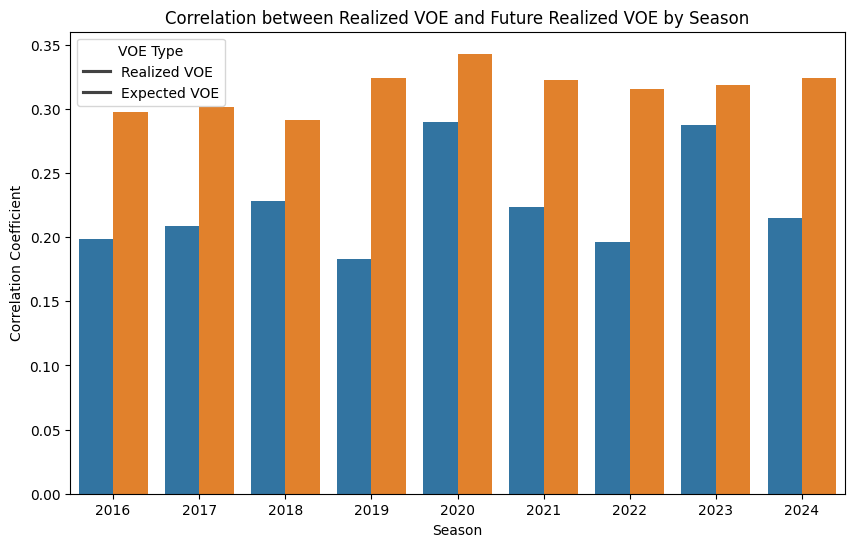

In [13]:
# Visualize correlations between causal VOE and future casual VOE for each year
# Bar graph of correlations
correlation_results = []
for season in seasons:
    season_data = pbp_weekly[pbp_weekly['season'] == season]
    corr_short = season_data['realized_voe'].corr(season_data['future_realized_voe'])
    corr_long = season_data['expected_voe'].corr(season_data['future_expected_voe'])
    correlation_results.append({
        'season': season,
        'corr_short': corr_short,
        'corr_long': corr_long
    })

correlation_df = pd.DataFrame(correlation_results)
plt.figure(figsize=(10, 6))
sns.barplot(x='season', y='value', hue='variable', 
            data=pd.melt(correlation_df, id_vars=['season'], value_vars=['corr_short', 'corr_long']))
plt.title('Correlation between Realized VOE and Future Realized VOE by Season')
plt.ylabel('Correlation Coefficient')
plt.xlabel('Season')
plt.legend(title='VOE Type', labels=['Realized VOE', 'Expected VOE'])
plt.show()

In [ ]:
pbp_weekly.groupby(['season', 'play_type']).agg({
    'realized_voe': 'sum', 'expected_voe': 'sum', 'fantasy_points_ppr': 'sum', 'residual_epa': 'sum'
})

realized_voe  expected_voe  fantasy_points_ppr  \
season play_type                                                    
2016   pass       -16816.725484  -3395.698980        48280.660156   
       run         -6176.049868   1188.150758        47790.218750   
2017   pass        35491.269628  -6839.161980        45215.101562   
       run         16541.067118     13.101905        45104.718750   
2018   pass       -28693.879337  -2144.440510        48239.339844   
       run         -2903.217830   1853.465259        48051.960938   
2019   pass         9409.473333  -5780.868836        49164.058594   
       run         -2728.392908   1603.751554        48865.398438   
2020   pass       -51148.837814   -925.818941        51421.578125   
       run        -15543.944385   3470.365119        51085.640625   
2021   pass       -31124.406930  -3070.110302        50299.660156   
       run          -325.241751   2127.450074        50056.859375   
2022   pass        14234.101144  -6109.050115        49018.980469   
       run         22399.742805   1151.527214        48787.281250   
2023   pass       101570.521200 -11213.736676        49030.500000   
       run         45632.895425   -924.235393        48802.359375   
2024   pass        38556.831328  -6963.385668        44167.179688   
       run         18018.873498   1263.389116        44007.359375   

                  residual_epa  
season play_type                
2016   pass            21027.0  
       run            -16701.2  
2017   pass             -463.9  
       run            -19817.3  
2018   pass            16687.4  
       run             -7903.1  
2019   pass            13464.2  
       run            -14518.0  
2020   pass            28804.3  
       run              -554.7  
2021   pass            11320.4  
       run             -5152.1  
2022   pass             -526.8  
       run             -1255.2  
2023   pass            -5886.2  
       run            -13322.6  
2024   pass            11149.9  
       run             -2645.8